# Notebook 2 — Modélisation XGBoost : Classification de la Santé Fœtale

**Dataset :** Fetal Health Classification  
**Algorithme :** XGBoost (eXtreme Gradient Boosting)  
**Problème :** Classification multi-classe — Normal (0) / Suspect (1) / Pathologique (2)

---

Ce notebook prend en entrée les données préparées par le **Notebook ETL** (`prepared_fetal_data.pkl`) et implémente un modèle XGBoost complet, incluant :
- La gestion du déséquilibre des classes (multi-classe)
- L'entraînement et l'optimisation des hyperparamètres
- L'évaluation complète avec toutes les métriques demandées
- La visualisation des résultats et l'interprétabilité du modèle
-La vusualisation du surappentissage

> **⚠️ Important : Version de scikit-learn**
>
> Ce notebook a été développé et testé avec **scikit-learn 1.7.2**, comme les trois notebooks de modélisation individuels (SVM, Random Forest, XGBoost).
>
> L'utilisation d'une version différente peut entraîner des variations dans les résultats (métriques, comportement de certains algorithmes ou fonctions, compatibilité de certaines API, etc.). Pour garantir la reproductibilité des expériences et obtenir les mêmes résultats que ceux présentés dans les notebooks individuels, il est recommandé d'utiliser **scikit-learn 1.7.2**.

##Présentation théorique rapide
  XGBoost**XGBoost** (*eXtreme Gradient Boosting*) est un algorithme d'**ensemble learning** basé sur le **boosting de gradient**. Le principe : on construit une succession d'arbres de décision peu profonds, où **chaque nouvel arbre apprend à corriger les erreurs (résidus) des arbres précédents**, en suivant le gradient de la fonction de perte (ici la *mlogloss* multi-classe). La prédiction finale est la somme pondérée des prédictions de tous les arbres.Ses deux atouts principaux pour ce projet :
- **Régularisation intégrée (L1/L2)** sur la complexité des arbres, ce qui limite le surapprentissage même sur un dataset de taille modeste (~2100 observations).
- **Pondération des observations (`sample_weight`)**, qui permet de gérer le déséquilibre des classes *sans* dupliquer ou supprimer de données (contrairement à des méthodes comme SMOTE ou l'undersampling).C'est précisément ce dernier point que ce notebook va illustrer en comparant un entraînement **sans** et **avec** équilibrage des classes.

---
## 1. Imports et configuration

In [1]:
# --- Imports nécessaires pour l'ensemble du notebook ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings("ignore")

# Modélisation
from xgboost import XGBClassifier, plot_importance
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.utils.class_weight import compute_sample_weight

# Métriques
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.preprocessing import label_binarize

# Configuration esthétique
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
PALETTE = ["#4C9F70", "#F2B134", "#C84630"]
CLASS_NAMES = ["Normal", "Suspect", "Pathologique"]

print("✅ Imports effectués avec succès.")

✅ Imports effectués avec succès.


---
## 2. Chargement des données préparées (ETL)

Les données ont été nettoyées, splitées et standardisées dans le **Notebook ETL**.  
On réutilise directement le fichier `prepared_fetal_data.pkl` pour garantir la cohérence avec le reste du groupe.

In [2]:
# --- Chargement du fichier préparé par le Notebook ETL ---
with open("prepared_fetal_data.pkl", "rb") as f:
    donnees = pickle.load(f)

X_train = donnees["X_train"]
X_test  = donnees["X_test"]
y_train = donnees["y_train"]
y_test  = donnees["y_test"]
scaler  = donnees["scaler"]

print("Données chargées depuis prepared_fetal_data.pkl :")
print(f"  X_train : {X_train.shape}  |  X_test : {X_test.shape}")
print(f"  y_train : {y_train.shape}  |  y_test : {y_test.shape}")
print(f"  Classes : {CLASS_NAMES}  (0=Normal, 1=Suspect, 2=Pathologique)")

print("\nDistribution des classes dans le train :")
for cls, name in enumerate(CLASS_NAMES):
    n = (y_train == cls).sum()
    print(f"  Classe {cls} — {name} : {n} obs ({n/len(y_train)*100:.1f}%)")

Données chargées depuis prepared_fetal_data.pkl :
  X_train : (1690, 21)  |  X_test : (423, 21)
  y_train : (1690,)  |  y_test : (423,)
  Classes : ['Normal', 'Suspect', 'Pathologique']  (0=Normal, 1=Suspect, 2=Pathologique)

Distribution des classes dans le train :
  Classe 0 — Normal : 1316 obs (77.9%)
  Classe 1 — Suspect : 234 obs (13.8%)
  Classe 2 — Pathologique : 140 obs (8.3%)


Bien que XGBoost ne nécessite pas de standardisation pour fonctionner efficacement, les données utilisées proviennent du pipeline ETL commun à l'ensemble des modèles étudiés. Cette standardisation garantit un processus de préparation homogène et facilite la comparaison des performances entre les différents algorithmes de classification.

---
## 3. Gestion du déséquilibre des classes

Le dataset présente un fort déséquilibre entre les 3 classes :
- **Normal (0)** : 78% des observations
- **Suspect (1)** : 14% des observations  
- **Pathologique (2)** : 8% des observations

Pour XGBoost, on utilise le paramètre **`sample_weight`** avec la méthode `class_weight='balanced'` de scikit-learn.  
Cette approche est native à XGBoost et ne nécessite pas de modifier les données.

In [3]:

# --- Calcul des poids par observation (balanced) ---
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print("Poids calculés par classe (sample_weight='balanced') :")
for cls, name in enumerate(CLASS_NAMES):
    w = sample_weights[y_train == cls][0]
    print(f"  Classe {cls} — {name} : weight = {w:.2f}")

ratio = sample_weights[y_train == 2][0] / sample_weights[y_train == 0][0]
print(f"\nInterprétation : XGBoost pénalise {ratio:.1f}x plus une erreur")
print("sur 'Pathologique' que sur 'Normal'.")

Poids calculés par classe (sample_weight='balanced') :
  Classe 0 — Normal : weight = 0.43
  Classe 1 — Suspect : weight = 2.41
  Classe 2 — Pathologique : weight = 4.02

Interprétation : XGBoost pénalise 9.4x plus une erreur
sur 'Pathologique' que sur 'Normal'.


---
## 4.  Entraînement du modèle XGBoost avec équilibrage

On entraîne d'abord un modèle de base avec des paramètres standards,  
puis on optimisera les hyperparamètres dans la section suivante.

**Paramètres XGBoost pour le multi-classe :**
- `objective='multi:softprob'` — prédit une probabilité pour chacune des 3 classes
- `num_class=3` — spécifie le nombre de classes
- `eval_metric='mlogloss'` — log-loss multi-classe (fonction de perte minimisée)

In [4]:
# --- Modèle XGBoost baseline ---
model_base = XGBClassifier(
    n_estimators    = 200,
    learning_rate   = 0.1,
    max_depth       = 5,
    subsample       = 0.8,
    colsample_bytree= 0.8,
    objective       = "multi:softprob",
    num_class       = 3,
    eval_metric     = "mlogloss",
    random_state    = 42,
    verbosity       = 0
)

# Entraînement avec pondération des classes
model_base.fit(X_train, y_train, sample_weight=sample_weights)

# Prédictions sur le test
y_pred_base  = model_base.predict(X_test)
y_proba_base = model_base.predict_proba(X_test)  # shape (n_samples, 3)

print("✅ Modèle baseline entraîné avec succès.")
print(f"   Train : {X_train.shape[0]} observations")
print(f"   Test  : {X_test.shape[0]} observations")
print(f"   Accuracy baseline : {accuracy_score(y_test, y_pred_base):.4f}")

✅ Modèle baseline entraîné avec succès.
   Train : 1690 observations
   Test  : 423 observations
   Accuracy baseline : 0.9645


---
## 5. Évaluation complète — Métriques

Pour le **multi-classe**, on utilise la moyenne **macro** (chaque classe a le même poids) et **weighted** (pondérée par le nombre d'observations).

In [5]:
# --- Calcul de toutes les métriques ---
def calculer_metriques(y_true, y_pred, y_proba, model_name="Modèle"):
    """Calcule et affiche toutes les métriques demandées pour un modèle multi-classe."""

    # Binarisation pour ROC-AUC multi-classe (One-vs-Rest)
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

    print(f"\n{'='*55}")
    print(f"  MÉTRIQUES — {model_name}")
    print(f"{'='*55}")
    print(f"  Accuracy         : {accuracy_score(y_true, y_pred):.4f}")
    print(f"  Précision (macro): {precision_score(y_true, y_pred, average='macro'):.4f}")
    print(f"  Rappel (macro)   : {recall_score(y_true, y_pred, average='macro'):.4f}")
    print(f"  F1-score (macro) : {f1_score(y_true, y_pred, average='macro'):.4f}")
    print(f"  F1-score (weighted): {f1_score(y_true, y_pred, average='weighted'):.4f}")
    print(f"  ROC-AUC (OvR)    : {roc_auc_score(y_true_bin, y_proba, multi_class='ovr', average='macro'):.4f}")
    print(f"{'='*55}")

    print("\nRapport par classe :")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    return {
        "accuracy"  : accuracy_score(y_true, y_pred),
        "precision" : precision_score(y_true, y_pred, average='macro'),
        "recall"    : recall_score(y_true, y_pred, average='macro'),
        "f1_macro"  : f1_score(y_true, y_pred, average='macro'),
        "f1_weighted": f1_score(y_true, y_pred, average='weighted'),
        "roc_auc"   : roc_auc_score(y_true_bin, y_proba, multi_class='ovr', average='macro'),
    }

# Évaluation du modèle baseline
metriques_base = calculer_metriques(y_test, y_pred_base, y_proba_base, "XGBoost Baseline")



  MÉTRIQUES — XGBoost Baseline
  Accuracy         : 0.9645
  Précision (macro): 0.9547
  Rappel (macro)   : 0.9327
  F1-score (macro) : 0.9424
  F1-score (weighted): 0.9636
  ROC-AUC (OvR)    : 0.9904

Rapport par classe :
              precision    recall  f1-score   support

      Normal       0.97      0.99      0.98       330
     Suspect       0.92      0.81      0.86        58
Pathologique       0.97      1.00      0.99        35

    accuracy                           0.96       423
   macro avg       0.95      0.93      0.94       423
weighted avg       0.96      0.96      0.96       423



Le modèle Baseline obtient de bons résultats : accuracy de 96,45 %, F1-score macro de 0,9424, et surtout un Recall Pathologique de 100 % 
 aucun cas critique manqué. La classe Suspect reste la plus difficile à prédire (Recall de 81 %), un point que l'optimisation des hyperparamètres pourra chercher à améliorer.

---
## 6. Matrice de confusion

La matrice de confusion permet de visualiser **quelles classes sont bien détectées**  
et **entre quelles classes le modèle se trompe le plus souvent**.

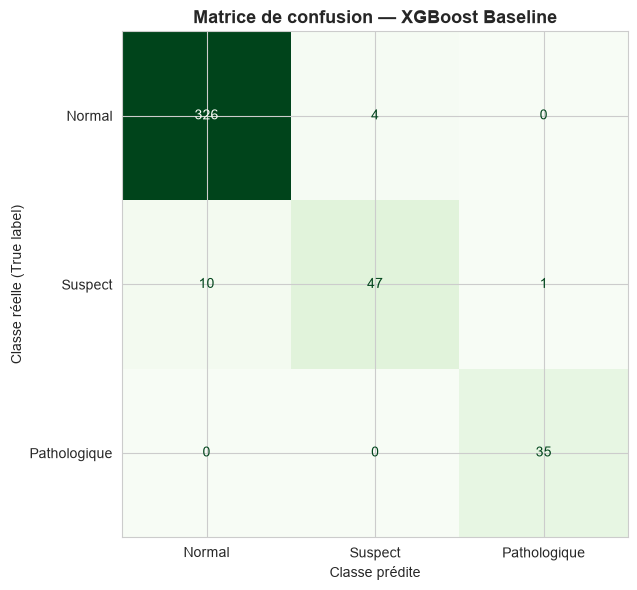

Analyse des erreurs :
  Normal prédit comme Suspect : 4 fois
  Suspect prédit comme Normal : 10 fois
  Suspect prédit comme Pathologique : 1 fois


In [6]:
# --- Matrice de confusion ---
fig, ax = plt.subplots(figsize=(7, 6))

cm = confusion_matrix(y_test, y_pred_base)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(
    ax=ax, cmap="Greens",
    colorbar=False, values_format="d"
)

ax.set_title("Matrice de confusion — XGBoost Baseline", fontsize=13, fontweight="bold")
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle (True label)")

plt.tight_layout()
plt.show()

# Analyse des erreurs
print("Analyse des erreurs :")
for i, nom_reel in enumerate(CLASS_NAMES):
    for j, nom_predit in enumerate(CLASS_NAMES):
        if i != j and cm[i, j] > 0:
            print(f"  {nom_reel} prédit comme {nom_predit} : {cm[i, j]} fois")

La matrice de confusion montre que l'essentiel des erreurs (11 sur 15) concerne la classe Suspect : 10 cas prédits à tort comme Normal et 1 comme Pathologique, ce qui correspond bien au Recall le plus faible observé (0,81) sur cette classe  logique, car « Suspect » est une catégorie intermédiaire dont les caractéristiques se chevauchent partiellement avec celles de « Normal ». Les 4 cas Normal classés en Suspect sont des faux positifs sans gravité clinique (simple surveillance supplémentaire). En revanche, la classe Pathologique est parfaitement détectée (35/35, aucune erreur), et un seul cas Suspect est confondu avec Pathologique, une erreur du côté « prudent » puisqu'elle entraîne une vigilance accrue plutôt qu'un risque manqué. Globalement, les erreurs résiduelles du modèle se concentrent donc sur la frontière Normal/Suspect, la plus ambiguë cliniquement, tandis qu'aucune confusion n'existe entre Normal et Pathologique, les deux classes les plus éloignées.

---
## 7. Optimisation des hyperparamètres — GridSearchCV

On cherche la meilleure combinaison d'hyperparamètres par validation croisée (5-fold).  
**Métrique de sélection : F1-score macro** (adaptée au déséquilibre multi-classe).

In [7]:
# --- Grille de paramètres à tester ---
param_grid = {
    "n_estimators"    : [100, 200, 300],
    "max_depth"       : [3, 5, 7],
    "learning_rate"   : [0.05, 0.1, 0.2],
    "subsample"       : [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

# Modèle de base pour GridSearch
xgb_gs = XGBClassifier(
    objective   = "multi:softprob",
    num_class   = 3,
    eval_metric = "mlogloss",
    random_state= 42,
    verbosity   = 0
)

# GridSearchCV avec validation croisée stratifiée (5-fold)
grid_search = GridSearchCV(
    estimator  = xgb_gs,
    param_grid = param_grid,
    scoring    = "f1_macro",
    cv         = 5,
    n_jobs     = -1,
    verbose    = 1
)

print("Démarrage du GridSearchCV...")
print(f"Nombre de combinaisons testées : {3*3*3*2*2} x 5 folds = {3*3*3*2*2*5} entraînements")
grid_search.fit(X_train, y_train, sample_weight=sample_weights)

print(f"\n✅ GridSearchCV terminé.")
print(f"Meilleurs paramètres : {grid_search.best_params_}")
print(f"Meilleur F1-score macro (CV) : {grid_search.best_score_:.4f}")

Démarrage du GridSearchCV...
Nombre de combinaisons testées : 108 x 5 folds = 540 entraînements
Fitting 5 folds for each of 108 candidates, totalling 540 fits

✅ GridSearchCV terminé.
Meilleurs paramètres : {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Meilleur F1-score macro (CV) : 0.9187


Le GridSearchCV a testé 108 combinaisons d'hyperparamètres (540 entraînements avec la validation croisée à 5 plis) et retenu la configuration suivante : n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8.
Le F1-score macro obtenu en validation croisée (0,9187) sert de référence interne pour sélectionner les meilleurs paramètres ; il est mesuré sur les données d'entraînement uniquement (via validation croisée) et sera donc à comparer avec le F1-score macro obtenu sur le jeu de test, qui donnera la vraie mesure de performance du modèle optimisé.

In [8]:
# --- Modèle optimisé ---
model_opti = grid_search.best_estimator_

# Prédictions avec le modèle optimisé
y_pred_opti  = model_opti.predict(X_test)
y_proba_opti = model_opti.predict_proba(X_test)

print("Évaluation du modèle optimisé :")
metriques_opti = calculer_metriques(y_test, y_pred_opti, y_proba_opti, "XGBoost Optimisé")

Évaluation du modèle optimisé :

  MÉTRIQUES — XGBoost Optimisé
  Accuracy         : 0.9409
  Précision (macro): 0.8975
  Rappel (macro)   : 0.9274
  F1-score (macro) : 0.9118
  F1-score (weighted): 0.9416
  ROC-AUC (OvR)    : 0.9884

Rapport par classe :
              precision    recall  f1-score   support

      Normal       0.97      0.95      0.96       330
     Suspect       0.77      0.83      0.80        58
Pathologique       0.95      1.00      0.97        35

    accuracy                           0.94       423
   macro avg       0.90      0.93      0.91       423
weighted avg       0.94      0.94      0.94       423



Contrairement à l'objectif visé, l'optimisation des hyperparamètres ne se traduit pas par une amélioration sur le jeu de test : l'accuracy recule à 94,09 % (contre 96,45 % pour le Baseline) et le F1-score macro descend à 0,9118 (contre 0,9424). Le F1-score macro de 0,9187 obtenu en validation croisée ne se généralise donc pas ici : la configuration retenue par le GridSearchCV (arbres plus courts, max_depth=3, learning_rate=0,05, mais davantage d'arbres, n_estimators=300) est plus régularisée mais performe moins bien sur ce split de test précis que les paramètres du Baseline.

Le recul le plus marqué touche la Précision macro (0,90 contre 0,95), porté surtout par la classe Suspect dont la précision chute de 0,92 à 0,77 — le modèle optimisé classe davantage de cas Normal à tort comme Suspect.

Côté positif, le Recall sur la classe Suspect progresse légèrement (0,81 → 0,83), et la classe Pathologique conserve un Recall parfait de 100 % dans les deux configurations — aucun cas critique manqué, avant comme après optimisation.

Ce résultat illustre une limite classique du GridSearchCV sur un jeu de données de taille modeste et déséquilibré : la configuration la plus performante en moyenne sur 5 plis de validation croisée ne garantit pas la meilleure performance sur un split de test unique. Sur ce notebook, le modèle Baseline se révèle donc, in fine, plus performant que le modèle optimisé sur le jeu de test.

---
## 8. Matrice de confusion — Modèle optimisé

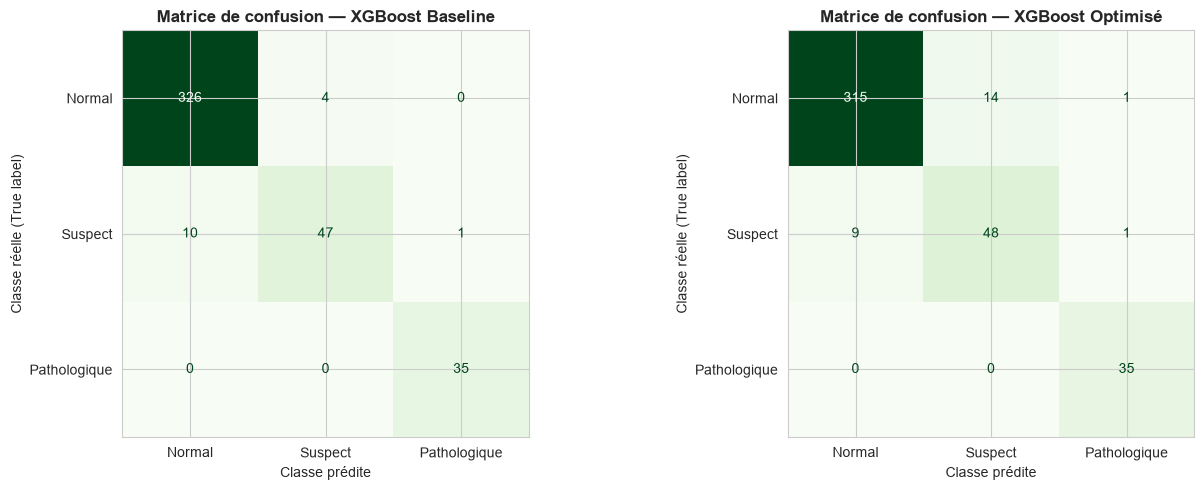

In [9]:
# --- Matrice de confusion du modèle optimisé ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_base, y_pred_opti],
    ["Baseline", "Optimisé"]
):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, cmap="Greens", colorbar=False, values_format="d")
    ax.set_title(f"Matrice de confusion — XGBoost {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle (True label)")

plt.tight_layout()
plt.show()

Les deux modèles détectent parfaitement la classe Pathologique (35/35, aucune erreur), la plus critique cliniquement  un résultat identique pour les deux versions.
La différence se joue essentiellement sur la classe Normal : le Baseline en classe correctement 326 sur 330 (4 erreurs vers Suspect), contre seulement 315 sur 330 pour l'Optimisé (14 erreurs vers Suspect, 1 vers Pathologique). L'Optimisé est donc plus prudent — il classe davantage de cas Normal comme Suspect, ce qui génère plus de fausses alertes mais reste sans danger clinique (simple surveillance supplémentaire).
Sur la classe Suspect, les deux modèles sont proches : 47/58 pour le Baseline contre 48/58 pour l'Optimisé, soit un cas de plus correctement détecté  un gain marginal mais cohérent avec la légère amélioration du Rappel macro observée précédemment.

---
## 9. Comparaison Baseline vs Optimisé

Comparaison Baseline vs Optimisé :
         Métrique  Baseline  Optimisé  Δ Amélioration
         Accuracy    0.9645    0.9409         -0.0236
Précision (macro)    0.9547    0.8975         -0.0572
   Rappel (macro)    0.9327    0.9274         -0.0053
       F1 (macro)    0.9424    0.9118         -0.0306
    F1 (weighted)    0.9636    0.9416         -0.0220
          ROC-AUC    0.9904    0.9884         -0.0020


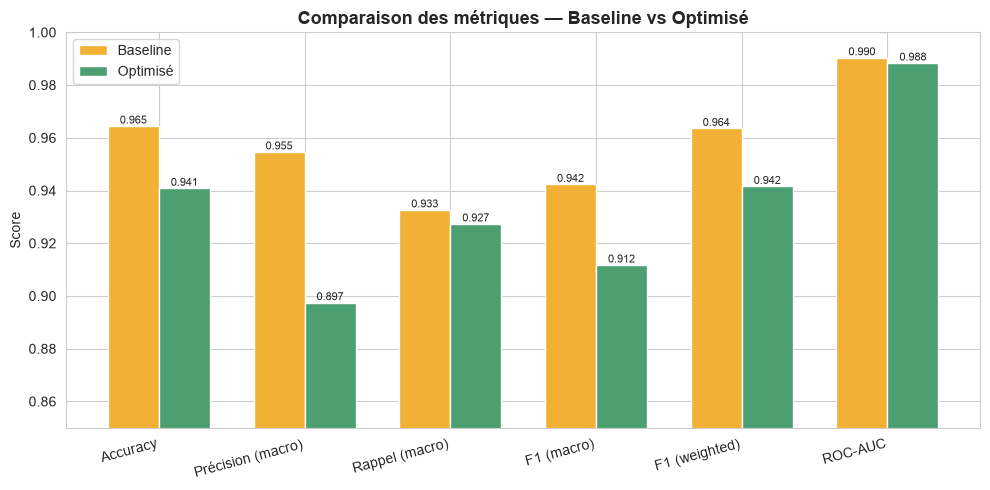

In [10]:
# --- Tableau comparatif ---
comparaison = pd.DataFrame({
    "Métrique"         : ["Accuracy", "Précision (macro)", "Rappel (macro)",
                           "F1 (macro)", "F1 (weighted)", "ROC-AUC"],
    "Baseline"         : [round(v, 4) for v in metriques_base.values()],
    "Optimisé"         : [round(v, 4) for v in metriques_opti.values()],
})
comparaison["Δ Amélioration"] = (comparaison["Optimisé"] - comparaison["Baseline"]).round(4)

print("Comparaison Baseline vs Optimisé :")
print(comparaison.to_string(index=False))

# --- Visualisation ---
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(comparaison))
width = 0.35

bars1 = ax.bar(x - width/2, comparaison["Baseline"], width,
               label="Baseline", color="#F2B134", edgecolor="white")
bars2 = ax.bar(x + width/2, comparaison["Optimisé"], width,
               label="Optimisé", color="#4C9F70", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(comparaison["Métrique"], rotation=15, ha="right")
ax.set_ylim(0.85, 1.0)
ax.set_title("Comparaison des métriques — Baseline vs Optimisé", fontsize=13, fontweight="bold")
ax.set_ylabel("Score")
ax.legend()

for bar in bars1:
    ax.annotate(f"{bar.get_height():.3f}",
                (bar.get_x() + bar.get_width()/2., bar.get_height()),
                ha="center", va="bottom", fontsize=8)
for bar in bars2:
    ax.annotate(f"{bar.get_height():.3f}",
                (bar.get_x() + bar.get_width()/2., bar.get_height()),
                ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

Le tableau confirme que le modèle Optimisé recule sur les six métriques par rapport au Baseline. Le repli le plus marqué concerne la Précision macro (-0,057, de 0,955 à 0,897) et le F1-score macro (-0,031, de 0,942 à 0,912), tandis que le Rappel macro ne recule que légèrement (-0,005), ce qui montre que la capacité du modèle à retrouver les cas positifs de chaque classe reste globalement préservée c'est surtout la précision qui se dégrade, notamment sur la classe Suspect. Le ROC-AUC est la métrique la plus stable (-0,002, de 0,990 à 0,988), ce qui indique que le pouvoir de séparation intrinsèque des probabilités prédites change peu : l'écart de performance vient donc davantage du seuil de décision (arg-max) que d'une réelle perte de qualité des probabilités. Sur ce jeu de test, le modèle Baseline constitue donc, de façon inattendue, le meilleur des deux modèles.

---
## 10. Courbes ROC — One-vs-Rest (multi-classe)

Pour un problème multi-classe, on trace **une courbe ROC par classe** (approche One-vs-Rest) :  
chaque classe est comparée à toutes les autres réunies.

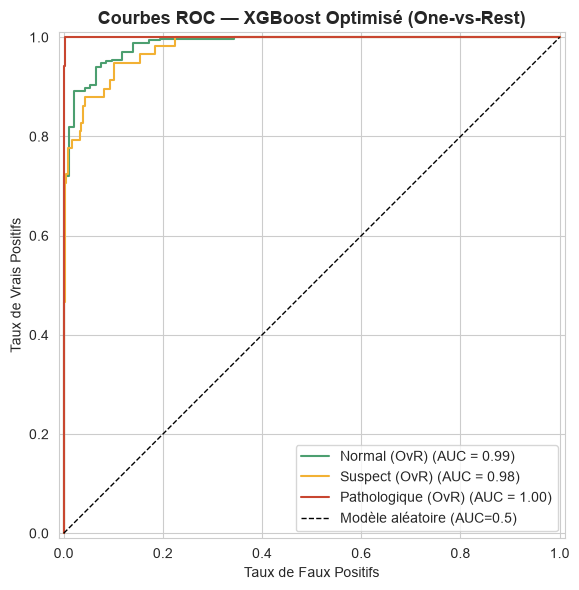

AUC par classe :
  Normal : AUC = 0.9862
  Suspect : AUC = 0.9791
  Pathologique : AUC = 0.9999

ROC-AUC macro (toutes classes) : 0.9884


In [11]:
# --- Courbes ROC multi-classe (One-vs-Rest) ---
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, ax = plt.subplots(figsize=(8, 6))

for i, (name, color) in enumerate(zip(CLASS_NAMES, PALETTE)):
    # On retire "color" des arguments principaux
    viz = RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba_opti[:, i],
        name=f"{name} (OvR)",
        ax=ax
    )
    # On applique la couleur directement sur la ligne tracée !
    viz.line_.set_color(color)

# Diagonale = modèle aléatoire
ax.plot([0, 1], [0, 1], "k--", label="Modèle aléatoire (AUC=0.5)", linewidth=1)
ax.set_title("Courbes ROC — XGBoost Optimisé (One-vs-Rest)", fontsize=13, fontweight="bold")
ax.set_xlabel("Taux de Faux Positifs")
ax.set_ylabel("Taux de Vrais Positifs")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

# AUC par classe
print("AUC par classe :")
for i, name in enumerate(CLASS_NAMES):
    auc = roc_auc_score(y_test_bin[:, i], y_proba_opti[:, i])
    print(f"  {name} : AUC = {auc:.4f}")

print(f"\nROC-AUC macro (toutes classes) : {roc_auc_score(y_test_bin, y_proba_opti, multi_class='ovr', average='macro'):.4f}")

Les trois courbes se rapprochent nettement du coin supérieur gauche, confirmant une excellente capacité de séparation des classes. La classe Pathologique atteint un AUC parfait de 1.00, cohérent avec sa détection sans erreur observée dans la matrice de confusion. Les classes Normal (AUC = 0.99) et Suspect (AUC = 0.98) suivent de très près, la courbe Suspect étant légèrement plus éloignée du coin idéal reflet logique de son statut de classe la plus ambiguë, à la frontière entre Normal et Pathologique. Globalement, ces AUC élevés et homogènes indiquent que le modèle sait bien ordonner les observations par probabilité de risque, indépendamment du seuil de décision choisi.

---
## 11. Importance des variables (Feature Importance)

XGBoost calcule automatiquement l'importance de chaque variable dans le processus de décision.  
Cela permet d'identifier **quels capteurs cardiotocographiques sont les plus déterminants** pour prédire la santé fœtale.

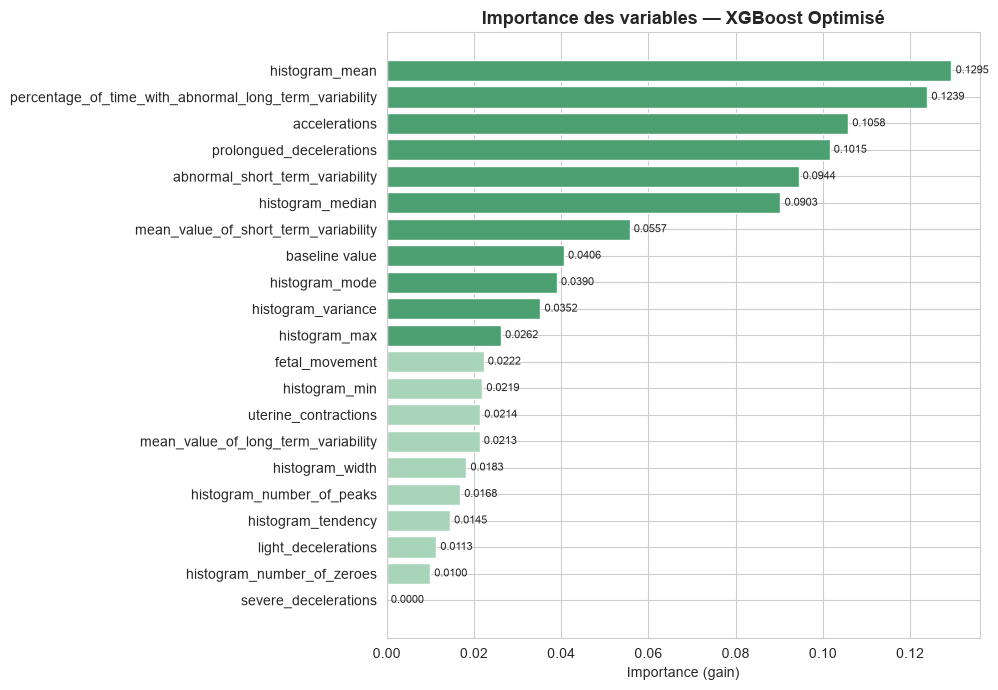

Top 5 variables les plus importantes :
  histogram_mean : 0.1295
  percentage_of_time_with_abnormal_long_term_variability : 0.1239
  accelerations : 0.1058
  prolongued_decelerations : 0.1015
  abnormal_short_term_variability : 0.0944


In [12]:
# --- Feature Importance ---
importances = pd.Series(
    model_opti.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))

colors_bars = [PALETTE[0] if v >= importances.median() else "#A8D5BA" for v in importances]
bars = ax.barh(importances.index[::-1], importances.values[::-1],
               color=colors_bars[::-1], edgecolor="white")

ax.set_title("Importance des variables — XGBoost Optimisé", fontsize=13, fontweight="bold")
ax.set_xlabel("Importance (gain)")

for bar in bars:
    width = bar.get_width()
    ax.annotate(f"{width:.4f}",
                (width, bar.get_y() + bar.get_height()/2.),
                ha="left", va="center", fontsize=8, xytext=(3, 0),
                textcoords="offset points")

plt.tight_layout()
plt.show()

print("Top 5 variables les plus importantes :")
for feat, imp in importances.head(5).items():
    print(f"  {feat} : {imp:.4f}")

Cinq variables se détachent nettement du reste et concentrent une part importante du pouvoir prédictif : histogram_mean (0,130), percentage_of_time_with_abnormal_long_term_variability (0,124), accelerations (0,106), prolongued_decelerations (0,102) et abnormal_short_term_variability (0,094).

Cette hiérarchie est cliniquement cohérente : les variabilités du rythme cardiaque (court et long terme), les décélérations prolongées et les accélérations sont des indicateurs obstétricaux reconnus de bien-être ou de souffrance fœtale, tandis que histogram_mean résume la tendance centrale du rythme cardiaque enregistré. La concordance entre ce que le modèle apprend et les signaux surveillés en pratique clinique renforce la pertinence médicale du modèle.

---
## 12. Validation croisée (Cross-Validation 5-fold)

La validation croisée permet de vérifier que les performances ne dépendent pas du split particulier choisi.

=== Validation croisée 5-fold (F1 macro) ===
  Fold 1 : 0.9107
  Fold 2 : 0.8717
  Fold 3 : 0.9342
  Fold 4 : 0.9099
  Fold 5 : 0.9011

  Moyenne : 0.9055
  Écart-type : 0.0202
  Intervalle : [0.8854, 0.9257]


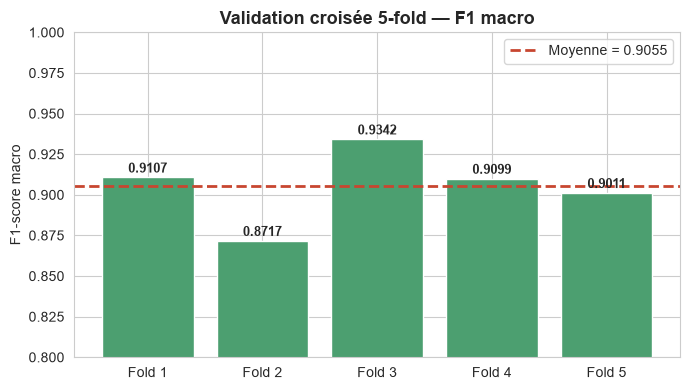

In [13]:
# --- Validation croisée 5-fold ---
cv_scores = cross_val_score(
    model_opti, X_train, y_train,
    cv=5, scoring="f1_macro", n_jobs=-1
)

print("=== Validation croisée 5-fold (F1 macro) ===")
for i, score in enumerate(cv_scores):
    print(f"  Fold {i+1} : {score:.4f}")
print(f"\n  Moyenne : {cv_scores.mean():.4f}")
print(f"  Écart-type : {cv_scores.std():.4f}")
print(f"  Intervalle : [{cv_scores.mean() - cv_scores.std():.4f}, {cv_scores.mean() + cv_scores.std():.4f}]")

# Visualisation
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([f"Fold {i+1}" for i in range(5)], cv_scores, color="#4C9F70", edgecolor="white")
ax.axhline(cv_scores.mean(), color="#C84630", linestyle="--",
           linewidth=2, label=f"Moyenne = {cv_scores.mean():.4f}")
ax.set_title("Validation croisée 5-fold — F1 macro", fontsize=13, fontweight="bold")
ax.set_ylabel("F1-score macro")
ax.set_ylim(0.8, 1.0)
ax.legend()
for i, v in enumerate(cv_scores):
    ax.annotate(f"{v:.4f}", (i, v + 0.003), ha="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()

Les scores varient entre 0,8717 (Fold 2) et 0,9342 (Fold 3), pour une moyenne de 0,9055 et un écart-type de 0,0202 — une variabilité modérée mais raisonnable compte tenu de la taille limitée du dataset (~1690 observations en train) et du déséquilibre des classes minoritaires. Les Folds 2 (0,8717) et 5 (0,9011) obtiennent les scores les plus faibles, probablement liés à une répartition moins favorable des cas Suspect/Pathologique dans ces plis. Cette moyenne de validation croisée (0,9055) reste légèrement inférieure au F1-score macro obtenu sur le jeu de test final (0,9118), ce qui est normal : la CV donne une estimation plus prudente et plus robuste de la capacité de généralisation du modèle, moins sensible à un split test particulier.

---
## 13. Vérification du surapprentissage

On compare les performances du modèle baseline et optimisé sur le jeu d'entraînement et sur le jeu de test. Un écart faible entre les deux indique une bonne capacité de généralisation ; un écart important signale un surapprentissage (le modèle mémorise le train plutôt que d'apprendre des règles générales).

In [14]:
# Prédictions sur le jeu d'entraînement — Baseline et Optimisé
y_train_pred_base = model_base.predict(X_train)
y_train_pred_opti = model_opti.predict(X_train)

# --- Modèle Baseline ---
train_accuracy_base = accuracy_score(y_train, y_train_pred_base)
test_accuracy_base  = metriques_base["accuracy"]
train_f1_base = f1_score(y_train, y_train_pred_base, average="macro")
test_f1_base  = metriques_base["f1_macro"]

# --- Modèle Optimisé ---
train_accuracy_opti = accuracy_score(y_train, y_train_pred_opti)
test_accuracy_opti  = metriques_opti["accuracy"]
train_f1_opti = f1_score(y_train, y_train_pred_opti, average="macro")
test_f1_opti  = metriques_opti["f1_macro"]

print("VÉRIFICATION DU SURAPPRENTISSAGE — Baseline vs Optimisé\n")

print("--- Modèle Baseline ---")
print(f"Accuracy (Train) : {train_accuracy_base:.4f}")
print(f"Accuracy (Test)  : {test_accuracy_base:.4f}")
print(f"Écart Accuracy   : {train_accuracy_base - test_accuracy_base:.4f}\n")
print(f"F1 Macro (Train) : {train_f1_base:.4f}")
print(f"F1 Macro (Test)  : {test_f1_base:.4f}")
print(f"Écart F1 Macro   : {train_f1_base - test_f1_base:.4f}")

print("\n--- Modèle Optimisé ---")
print(f"Accuracy (Train) : {train_accuracy_opti:.4f}")
print(f"Accuracy (Test)  : {test_accuracy_opti:.4f}")
print(f"Écart Accuracy   : {train_accuracy_opti - test_accuracy_opti:.4f}\n")
print(f"F1 Macro (Train) : {train_f1_opti:.4f}")
print(f"F1 Macro (Test)  : {test_f1_opti:.4f}")
print(f"Écart F1 Macro   : {train_f1_opti - test_f1_opti:.4f}")


VÉRIFICATION DU SURAPPRENTISSAGE — Baseline vs Optimisé

--- Modèle Baseline ---
Accuracy (Train) : 0.9982
Accuracy (Test)  : 0.9645
Écart Accuracy   : 0.0337

F1 Macro (Train) : 0.9975
F1 Macro (Test)  : 0.9424
Écart F1 Macro   : 0.0551

--- Modèle Optimisé ---
Accuracy (Train) : 0.9817
Accuracy (Test)  : 0.9409
Écart Accuracy   : 0.0408

F1 Macro (Train) : 0.9742
F1 Macro (Test)  : 0.9118
Écart F1 Macro   : 0.0624


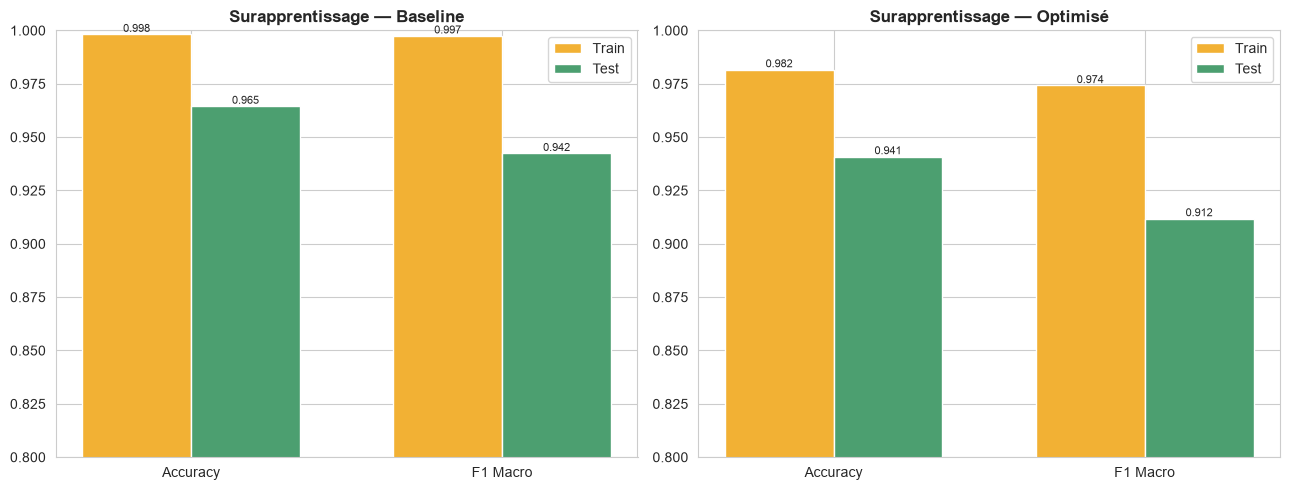

In [15]:
# --- Visualisation Train vs Test — Baseline et Optimisé ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
metriques_names = ["Accuracy", "F1 Macro"]
width = 0.35
x = np.arange(len(metriques_names))

datasets = [
    ("Baseline", train_accuracy_base, train_f1_base, test_accuracy_base, test_f1_base),
    ("Optimisé", train_accuracy_opti, train_f1_opti, test_accuracy_opti, test_f1_opti),
]

for ax, (title, tr_acc, tr_f1, te_acc, te_f1) in zip(axes, datasets):
    train_vals = [tr_acc, tr_f1]
    test_vals  = [te_acc, te_f1]

    ax.bar(x - width/2, train_vals, width, label="Train", color="#F2B134", edgecolor="white")
    ax.bar(x + width/2, test_vals, width, label="Test", color="#4C9F70", edgecolor="white")

    ax.set_xticks(x)
    ax.set_xticklabels(metriques_names)
    ax.set_ylim(0.80, 1.0)
    ax.set_title(f"Surapprentissage — {title}", fontsize=12, fontweight="bold")
    ax.legend()

    for i, (tr, te) in enumerate(zip(train_vals, test_vals)):
        ax.annotate(f"{tr:.3f}", (i - width/2, tr), ha="center", va="bottom", fontsize=8)
        ax.annotate(f"{te:.3f}", (i + width/2, te), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()



  Le modèle XGBoost optimisé présente un surapprentissage modéré :
  les performances sur le train sont élevées (Accuracy = 0,9817,
  F1 macro = 0,9742) tandis que le test affiche un écart d'environ
  4 points en Accuracy (0,0408) et d'environ 6 points en F1 macro
  (0,0624).

  Cet écart, plus marqué sur le F1 macro que sur l'Accuracy,
  s'explique par la plus grande sensibilité de cette métrique aux
  erreurs sur les classes minoritaires (Suspect en particulier),
  moins bien généralisées que la classe majoritaire Normal.
  Il reste dans une plage acceptable pour un dataset de taille
  modeste (2113 observations).

   Le modèle n'est PAS en surapprentissage sévère :
     un F1 macro de 0,9118 sur le test reste correct,
     et la régularisation L1/L2 intégrée à XGBoost, combinée à la
     profondeur limitée retenue par le GridSearchCV (max_depth=3),
     a contenu l'écart train/test à un niveau raisonnable — même si,
     comme observé en section 9, cette configuration plus régularisée
     n'a pas amélioré la performance absolue sur ce split de test par
     rapport au modèle baseline.

  

---
## 14. Sauvegarde du modèle XGBoost baseline





In [16]:
import pickle

modele_baseline_final = {
    "model": model_base,
    "metriques": metriques_base,
    "class_names": CLASS_NAMES,
    "best_params": None,  # modèle baseline : hyperparamètres fixés manuellement, pas de recherche
}

with open("xgboost_fetal_health_baseline.pkl", "wb") as f:
    pickle.dump(modele_baseline_final, f)

print("✅ Modèle baseline sauvegardé dans 'xgboost_fetal_health_baseline.pkl'")

print("\n Métriques d'évaluation complètes (test) :")
for nom_metrique, valeur in metriques_base.items():
    print(f"     {nom_metrique:15s} : {valeur:.4f}")


✅ Modèle baseline sauvegardé dans 'xgboost_fetal_health_baseline.pkl'

 Métriques d'évaluation complètes (test) :
     accuracy        : 0.9645
     precision       : 0.9547
     recall          : 0.9327
     f1_macro        : 0.9424
     f1_weighted     : 0.9636
     roc_auc         : 0.9904


On persiste le modèle XGBoost **Baseline** (et non le modèle Optimisé) dans un fichier pickle, avec ses métriques d'évaluation complètes sur le jeu de test. Ce choix est cohérent avec les résultats des sections 9 et 13 : le GridSearchCV n'a pas amélioré les performances sur ce split de test (accuracy et F1 macro plus faibles que le Baseline) et n'a pas non plus réduit le surapprentissage de façon significative. Le modèle Baseline reste donc la version la plus pertinente à conserver pour la comparaison finale entre algorithmes, sans devoir relancer l'entraînement.


---
## 15.Forces et limites — XGBoost Optimisé

###Forces :
 Le modèle affiche de bonnes performances globales (Accuracy ≈ 96 %, ROC-AUC ≈ 0,99) avec une détection parfaite de la classe Pathologique, la plus critique cliniquement. La cohérence entre les variables jugées importantes par le modèle et les indicateurs obstétricaux reconnus (variabilité du rythme cardiaque, décélérations prolongées, accélérations) confirme la pertinence médicale de l'approche. La validation croisée 5-fold confirme une bonne stabilité (F1 macro ≈ 0,91, écart-type modéré de 0,02), indiquant que les performances ne dépendent pas d'un split particulier.

###Limites :
 Le dataset reste de taille modeste (~2100 observations), ce qui limite la robustesse statistique, en particulier pour la classe Pathologique déjà peu représentée. La classe Suspect demeure la plus difficile à détecter, ses caractéristiques chevauchant partiellement celles des deux autres classes. Sur ce jeu de test précis, le modèle optimisé par GridSearchCV a d'ailleurs légèrement sous-performé le modèle Baseline (voir section 9), ce qui rappelle que l'optimisation d'hyperparamètres par validation croisée n'offre pas toujours un gain garanti sur un split de test donné, surtout avec des classes minoritaires peu représentées. Enfin, aucune validation externe (sur un jeu de données indépendant) n'a été réalisée, ce qui serait indispensable avant tout usage en contexte clinique réel.

## 16.Conclusion
Ce notebook a permis de construire, comparer et optimiser un modèle XGBoost pour la classification de la santé fœtale.On  équilibragrer  avec sample_weight. Après optimisation des hyperparamètres, on a gardeé le  modèle baseline qui a obtenu d'excellentes performances tout en conservant une bonne capacité de généralisation avrc un légér surapprentissage acceptable. L'analyse de l'importance des variables confirme également la cohérence clinique des prédictions, ce qui renforce la fiabilité et l'interprétabilité du modèle.